# Etapa 2: análise exploratória

Entrada: `data/processed/renda.csv`, gerado pela etapa 1.

A etapa responde a cinco perguntas antes de qualquer modelo:

1. As classes estão equilibradas?
2. Como os atributos numéricos se distribuem?
3. Quais atributos se relacionam com a renda?
4. Como a renda varia entre os grupos de raça e sexo, que ficam fora dos modelos?
5. Até onde vai uma regra simples?

Gráficos e tabelas usam os nomes em português de `config.NOMES`; o código e as categorias mantêm os nomes originais da base (em inglês).

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import config

base = pd.read_csv(config.PROCESSED_CSV)
alvo = base[config.TARGET]
MEDIA = alvo.mean() * 100
COR = "tab:blue"
print(base.shape)
print(f"% que ganha >50K na base: {MEDIA:.1f}")


def barras_taxa(ax, taxa, titulo, horizontal=False):
    """Barras com o % de >50K por grupo e a média da base como linha tracejada."""
    if horizontal:
        ax.barh(range(len(taxa)), taxa.values, color=COR, height=0.7)
        ax.set_yticks(range(len(taxa)), taxa.index)
        ax.axvline(MEDIA, color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel("% que ganha >50K")
        ax.invert_yaxis()
    else:
        ax.bar(range(len(taxa)), taxa.values, color=COR, width=0.7)
        ax.set_xticks(range(len(taxa)), taxa.index)
        ax.axhline(MEDIA, color="gray", linestyle="--", linewidth=1)
        ax.set_ylabel("% que ganha >50K")
    ax.set_title(titulo, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

(30139, 13)
% que ganha >50K na base: 24.9


## 1. Balanço das classes

In [2]:
contagem = alvo.map({1: ">50K", 0: "<=50K"}).value_counts()
pd.DataFrame({"pessoas": contagem, "%": (100 * contagem / len(base)).round(1)})

,pessoas,%
income,,
<=50K,22633,75.1
>50K,7506,24.9


Três em cada quatro pessoas ganham até 50 mil dólares por ano. Um modelo que responde sempre `<=50K` acerta 75,1% sem aprender nada: esse é o piso. O desbalanceamento (3 para 1) é maior que o da base de empréstimos (1,6 para 1), e a classe que interessa, `>50K`, é a menor. Por isso:

- a divisão treino-teste e a validação cruzada serão estratificadas, mantendo os 24,9% em todas as partes;
- a acurácia não basta: o F1 macro, a AUC e a matriz de confusão mostram se o modelo encontra quem ganha mais de 50 mil, e não só os 75% fáceis.

## 2. Distribuições dos atributos numéricos

Um histograma por atributo numérico. Ganho e perda de capital são zero para a grande maioria; os histogramas deles mostram só os valores acima de zero, e o título informa quantas pessoas são.

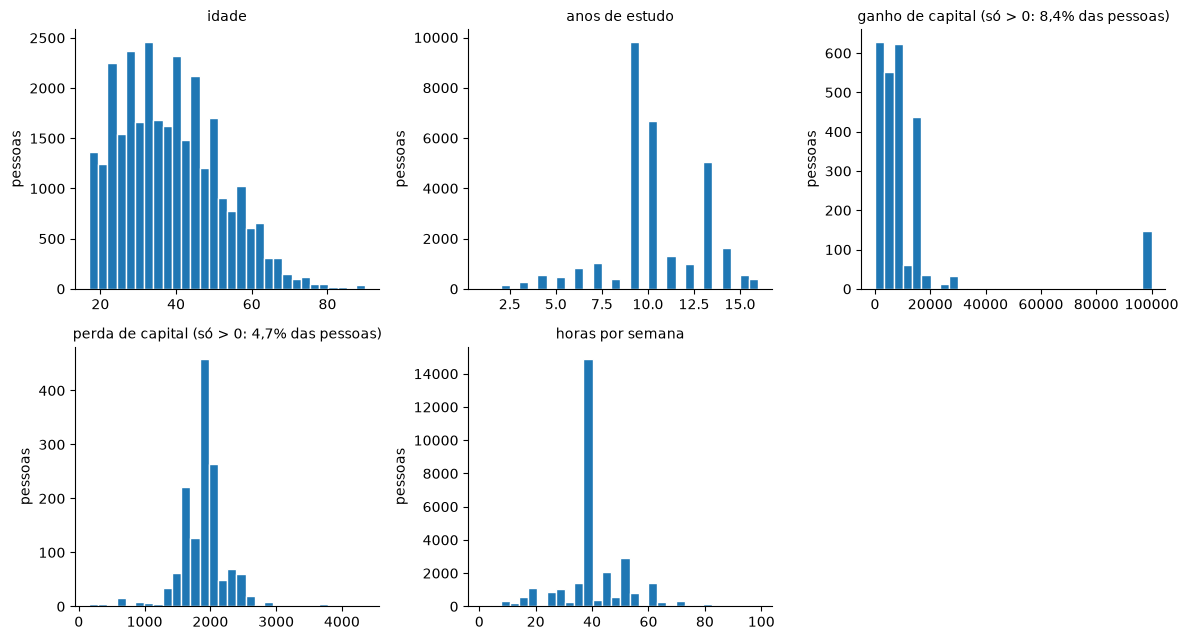

,age,education.num,capital.gain,capital.loss,hours.per.week
count,30139.0,30139.0,30139.0,30139.0,30139.0
mean,38.4,10.1,1092.8,88.4,40.9
std,13.1,2.5,7409.1,404.4,12.0
min,17.0,1.0,0.0,0.0,1.0
25%,28.0,9.0,0.0,0.0,40.0
50%,37.0,10.0,0.0,0.0,40.0
75%,47.0,13.0,0.0,0.0,45.0
max,90.0,16.0,99999.0,4356.0,99.0


In [3]:
fig, eixos = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, coluna in zip(eixos.flat, config.NUMERICAS):
    valores = base[coluna]
    titulo = config.NOMES[coluna]
    if coluna.startswith("capital"):
        valores = valores[valores > 0]
        parte = f"{len(valores) / len(base) * 100:.1f}".replace(".", ",")
        titulo += f" (só > 0: {parte}% das pessoas)"
    ax.hist(valores, bins=30, color=COR, edgecolor="white")
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel("pessoas")
    ax.spines[["top", "right"]].set_visible(False)
eixos.flat[-1].axis("off")
plt.tight_layout()
plt.show()

base[config.NUMERICAS].describe().round(1)

In [4]:
print("ganho de capital igual a zero:", f"{(base['capital.gain'] == 0).mean() * 100:.1f}%")
print("perda de capital igual a zero:", f"{(base['capital.loss'] == 0).mean() * 100:.1f}%")
print("ganho de capital = 99.999:", int((base["capital.gain"] == 99999).sum()), "pessoas")
print("exatamente 40 horas por semana:", f"{(base['hours.per.week'] == 40).mean() * 100:.1f}%")

ganho de capital igual a zero: 91.6%
perda de capital igual a zero: 95.3%
ganho de capital = 99.999: 148 pessoas
exatamente 40 horas por semana: 47.2%


Ao contrário da base de empréstimos, as distribuições têm a cara de dados reais:

- **Idade:** concentrada entre 25 e 50 anos e caindo depois dos 60 (o censo inclui só quem tem 17 anos ou mais).
- **Anos de estudo:** picos em 9 (ensino médio completo), 10 (faculdade incompleta) e 13 (graduação).
- **Horas por semana:** 47,2% trabalham exatamente 40 horas, a jornada padrão nos EUA.
- **Ganho e perda de capital:** zero para 91,6% e 95,3% das pessoas. Entre quem tem ganho, há 148 pessoas com exatamente 99.999, um valor que parece um teto do questionário, não um valor real.

Duas consequências para os modelos. As escalas são muito diferentes (horas vão até 99, ganho de capital até 99.999), e a SVM mede distâncias: sem padronização, o ganho de capital dominaria todos os outros atributos. E a assimetria do ganho de capital (quase tudo zero, poucos valores enormes) continua mesmo depois da padronização; é uma característica a observar nos resultados.

## 3. Atributos numéricos e renda

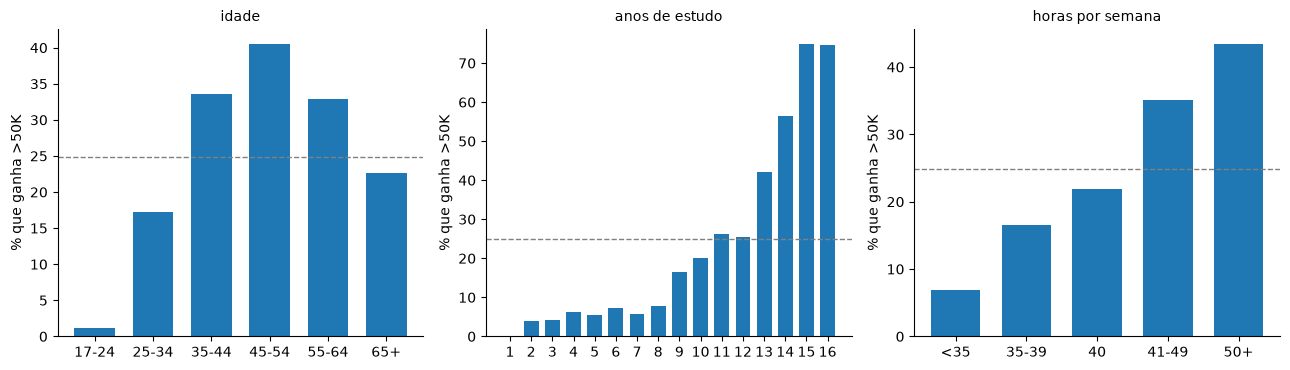

ganho de capital: % >50K com valor > 0 = 62.8 | com zero = 21.4
perda de capital: % >50K com valor > 0 = 51.6 | com zero = 23.6


In [5]:
faixas = {
    "age": pd.cut(base["age"], [17, 25, 35, 45, 55, 65, 91], right=False,
                  labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]),
    "education.num": base["education.num"],
    "hours.per.week": pd.cut(base["hours.per.week"], [0, 35, 40, 41, 50, 100], right=False,
                             labels=["<35", "35-39", "40", "41-49", "50+"]),
}
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (coluna, faixa) in zip(eixos, faixas.items()):
    taxa = alvo.groupby(faixa, observed=True).mean() * 100
    barras_taxa(ax, taxa, config.NOMES[coluna])
plt.tight_layout()
plt.show()

for coluna in ["capital.gain", "capital.loss"]:
    tem = base[coluna] > 0
    print(f"{config.NOMES[coluna]}: % >50K com valor > 0 = {alvo[tem].mean() * 100:.1f} | "
          f"com zero = {alvo[~tem].mean() * 100:.1f}")

A linha tracejada é a média da base (24,9%).

- **Idade:** a renda alta cresce até os 45-54 anos (40,5%) e cai depois; entre 17 e 24 anos, quase ninguém ganha mais de 50 mil (1,2%). A relação não é uma reta, é uma curva com pico.
- **Anos de estudo:** até o ensino médio incompleto (8 anos), menos de 8% ganham mais de 50 mil; com graduação (13), 42%; com mestrado (14), 57%; com doutorado ou formação profissional (15 e 16), 75%.
- **Horas por semana:** quem trabalha menos de 35 horas tem 6,9%; quem trabalha 50 horas ou mais, 43,4%.
- **Capital:** ter algum ganho de capital triplica a chance (62,8% contra 21,4%); ter perda de capital também aumenta (51,6% contra 23,6%), provavelmente porque só quem tem investimentos registra perdas.

A curva da idade é um exemplo de relação que uma fronteira reta não captura bem: a renda sobe e depois desce. É um caso em que o kernel RBF pode ajudar.

## 4. Correlações entre atributos numéricos

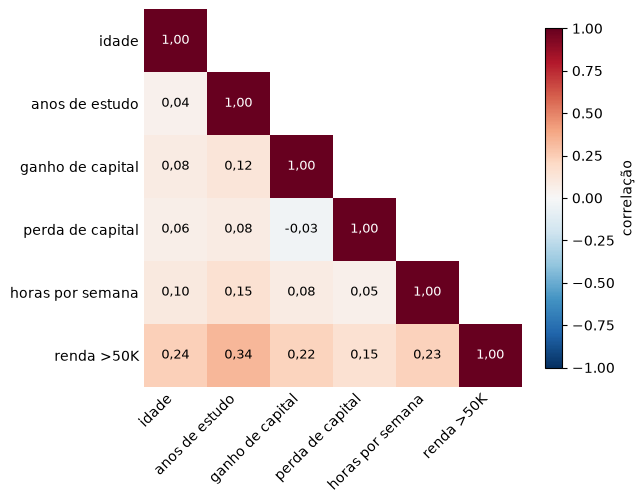

In [6]:
colunas = config.NUMERICAS + [config.TARGET]
corr = base[colunas].corr()
rotulos = [config.NOMES[c] for c in colunas]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
mascara = pd.DataFrame(False, index=corr.index, columns=corr.columns)
for i in range(len(corr)):
    for j in range(i + 1, len(corr)):
        mascara.iloc[i, j] = True
im = ax.imshow(corr.mask(mascara), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), rotulos, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), rotulos)
ax.tick_params(length=0)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}".replace(".", ","), ha="center", va="center",
                fontsize=9, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlação")
plt.tight_layout()
plt.show()

Os atributos numéricos são quase independentes entre si: a maior correlação entre dois deles é 0,15 (anos de estudo e horas). Não há o bloco redundante da base de empréstimos. Cada atributo traz informação própria.

Na última linha, a correlação com a renda: anos de estudo 0,34, idade 0,24, horas 0,23, ganho de capital 0,22, perda de capital 0,15. Nenhum atributo sozinho decide a renda, ao contrário do score de crédito nos empréstimos (0,77). A correlação mede só relações em linha reta, então subestima a idade, cuja relação com a renda tem pico (seção 3).

## 5. Atributos categóricos e renda

Para cada categoria, o % de pessoas que ganha mais de 50 mil; entre parênteses, quantas pessoas há na categoria. Categorias ordenadas da taxa mais alta para a mais baixa.

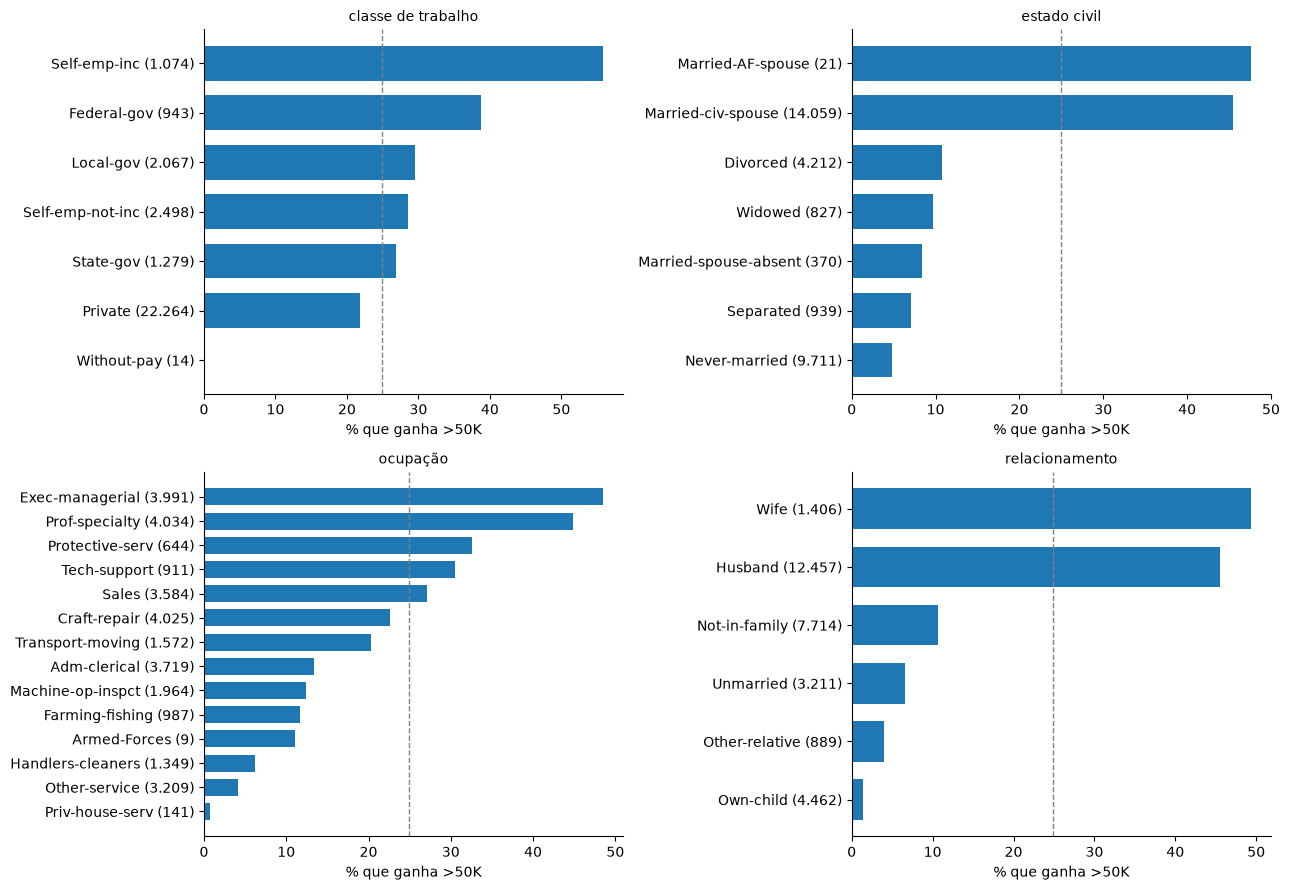

In [7]:
fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna in zip(eixos.flat, ["workclass", "marital.status", "occupation", "relationship"]):
    grupos = alvo.groupby(base[coluna]).agg(["mean", "size"]).sort_values("mean", ascending=False)
    taxa = grupos["mean"] * 100
    taxa.index = [f"{nome} ({n:,})".replace(",", ".") for nome, n in zip(grupos.index, grupos["size"])]
    barras_taxa(ax, taxa, config.NOMES[coluna], horizontal=True)
plt.tight_layout()
plt.show()

- **Estado civil e relacionamento** são os mais fortes: casados (*Married-civ-spouse*) têm 45,5% de renda alta, contra 4,8% de quem nunca casou. Em relacionamento, esposas (*Wife*) têm 49,4%, maridos (*Husband*) 45,6% e filhos (*Own-child*) 1,4%. As duas colunas dizem quase a mesma coisa: quem é marido ou esposa é casado.
- **Ocupação:** gerentes e executivos (*Exec-managerial*) e profissionais de nível superior (*Prof-specialty*) ficam perto de 45-48%; serviços gerais (*Other-service*) e serviços domésticos (*Priv-house-serv*), abaixo de 5%.
- **Classe de trabalho:** autônomos com empresa (*Self-emp-inc*) chegam a 55,9%; o setor privado, que tem 74% das pessoas, fica em 21,9%.

Parte do efeito do estado civil vem da idade: quem nunca casou tem 28,5 anos em média, contra 42,8 dos casados, e a renda alta é rara antes dos 25 anos (seção 3). Os modelos vão pesar os atributos em conjunto e separar o que é de cada um.

In [8]:
pais = base["native.country"]
print(f"nascidos nos EUA: {(pais == 'United-States').mean() * 100:.1f}% das pessoas")
grupos = alvo.groupby(pais).agg(["size", "mean"]).sort_values("size", ascending=False)
grupos["mean"] = (grupos["mean"] * 100).round(1)
grupos.columns = ["pessoas", "% >50K"]
print(f"países com menos de 100 pessoas: {(grupos['pessoas'] < 100).sum()} de {len(grupos)}")
grupos.head(8)

nascidos nos EUA: 91.2% das pessoas
países com menos de 100 pessoas: 33 de 41


,pessoas,% >50K
native.country,,
United-States,27487,25.4
Mexico,606,5.4
Philippines,188,31.9
Germany,128,34.4
Puerto-Rico,109,11.0
Canada,107,33.6
El-Salvador,100,9.0
India,100,40.0


O país de origem é muito concentrado: 91,2% nasceram nos EUA, e a maioria dos 41 países tem menos de 100 pessoas. No one-hot, viram colunas quase sempre zero, com pouca informação cada. A diferença maior é o México (5% de renda alta, contra 25% dos nascidos nos EUA).

## 6. Raça e sexo

Raça e sexo não entram nos modelos (`config.SENSIVEIS`). Esta seção descreve a base como ela é: um retrato do censo dos EUA de 1994. As diferenças abaixo são uma descrição dos dados daquele ano, não uma relação de causa.

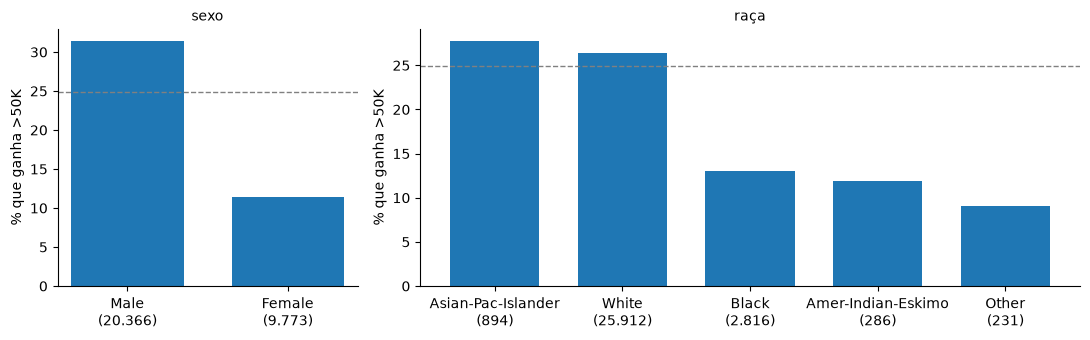

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 2.2]})
for ax, coluna in zip(eixos, config.SENSIVEIS[::-1]):
    grupos = alvo.groupby(base[coluna]).agg(["mean", "size"]).sort_values("mean", ascending=False)
    taxa = grupos["mean"] * 100
    taxa.index = [f"{nome}\n({n:,})".replace(",", ".") for nome, n in zip(grupos.index, grupos["size"])]
    barras_taxa(ax, taxa, config.NOMES[coluna])
plt.tight_layout()
plt.show()

Na base, 31,4% dos homens e 11,4% das mulheres ganham mais de 50 mil dólares. Entre os grupos de raça, brancos (26,4%) e asiáticos (27,7%) ficam acima da média, e negros (13,0%), indígenas (11,9%) e outros (9,1%) abaixo. Os grupos também têm tamanhos muito diferentes: 68% das pessoas são homens e 86% são brancos.

Tirar as duas colunas do modelo não garante que ele ignore essas diferenças, porque outros atributos carregam a mesma informação. A tabela mostra o caso mais forte:

In [10]:
pd.crosstab(base["relationship"], base["sex"], margins=True, margins_name="total")

sex,Female,Male,total
relationship,,,
Husband,1,12456,12457
Not-in-family,3560,4154,7714
Other-relative,386,503,889
Own-child,1959,2503,4462
Unmarried,2462,749,3211
Wife,1405,1,1406
total,9773,20366,30139


Das 12.457 pessoas marcadas como marido (*Husband*), 12.456 são homens; das 1.406 esposas (*Wife*), 1.405 são mulheres. Para os casados, o relacionamento revela o sexo quase sem erro. O modelo pode aprender "marido → renda alta", que na prática repete "homem → renda alta". Por isso, depois da previsão, os erros serão comparados entre homens e mulheres: é a forma de verificar se o viés voltou por esse caminho.

## 7. Até onde vai uma regra simples

Nos empréstimos, uma regra de uma linha ("aprova se score ≥ 550") acertava 95,4%. Aqui, a melhor regra de uma pergunta seria olhar o estado civil:

In [11]:
casado = base["marital.status"] == "Married-civ-spouse"
print(f"casados: {casado.mean() * 100:.1f}% das pessoas, {alvo[casado].mean() * 100:.1f}% delas ganham >50K")
print(f"regra 'casado → >50K': acerta {(casado.astype(int) == alvo).mean() * 100:.1f}%")
print(f"regra 'sempre <=50K':  acerta {(alvo == 0).mean() * 100:.1f}%")

casados: 46.6% das pessoas, 45.5% delas ganham >50K
regra 'casado → >50K': acerta 70.9%
regra 'sempre <=50K':  acerta 75.1%


Mesmo entre os casados, a maioria (54,5%) ganha até 50 mil. Então a regra "casado → >50K" acerta só 70,9%, menos que o chute. Uma pergunta só não basta: o melhor que ela consegue é empatar com o chute de 75,1%. Com duas perguntas, aparece uma regra útil:

In [12]:
regra = (casado & (base["education.num"] >= 13)) | (~casado & (base["capital.gain"] > 7073))
print(f"regra de duas perguntas: acerta {(regra.astype(int) == alvo).mean() * 100:.1f}%")
pd.crosstab(regra.map({True: ">50K", False: "<=50K"}), alvo.map({1: ">50K", 0: "<=50K"}),
            rownames=["regra prevê"], colnames=["renda real"])

regra de duas perguntas: acerta 82.4%


renda real,<=50K,>50K
regra prevê,,
<=50K,21496,4163
>50K,1137,3343


A regra "ganha mais de 50 mil se for casado com graduação ou mais, ou se não for casado e tiver ganho de capital acima de 7.073" acerta 82,4%. Os limiares (13 anos de estudo e 7.073) são os que uma árvore de profundidade 2 escolhe olhando a base inteira; nos modelos, regras como essa são aprendidas só com o treino.

**Resultado.** Resumo da etapa:

- **Classes:** 24,9% ganham mais de 50 mil (3 para 1). O piso é 75,1%; a divisão será estratificada, e F1, AUC e matriz de confusão completam a acurácia.
- **Dados reais:** distribuições com a cara de um censo (jornada de 40 horas, picos de escolaridade), ao contrário da base sintética de empréstimos.
- **Escalas e assimetria:** escalas muito diferentes e ganho de capital quase sempre zero. A padronização é obrigatória para a SVM.
- **Nenhum atributo decisivo:** as correlações com a renda vão de 0,15 a 0,34, e estado civil, escolaridade, idade, ocupação e capital contribuem juntos. Uma pergunta só não supera o chute; duas chegam a 82,4%.
- **Relações curvas:** a renda sobe e desce com a idade, um caso em que o kernel RBF pode superar a fronteira reta.
- **Raça e sexo:** diferenças grandes na base (31,4% contra 11,4% por sexo); o relacionamento revela o sexo dos casados, então os erros serão comparados por grupo.

A régua para os modelos vai de 75,1% (o chute) a 97,1% (o teto calculado na curadoria), com 82,4% para uma regra de duas perguntas.